# Day 069 | CNN — Image Classification
## 100 Days of ML for Geotechnical Engineering

| | |
|---|---|
| **Author** | Ripon Chandra Malo |
| **Phase** | 4 — Deep Learning |
| **Topic** | 2D CNN for Image Classification |
| **Tools** | PyTorch, NumPy, Matplotlib |
| **Geo Problem** | Classifying synthetic soil texture images — sand, clay, gravel (28×28 grayscale) |

---

## Concept Overview

| Concept | Description | Soil Texture Analogy |
|---|---|---|
| Conv2d(in, out, k) | Slides a 2D filter over height×width | k×k pixel window scanning texture pattern |
| MaxPool2d(2) | Takes max in each 2×2 spatial region | Reduces image to essential texture features |
| Feature maps | One output channel per filter | 16 different texture detectors |
| Flatten | H×W×C → 1D vector | Compact texture descriptor for FC layer |
| CrossEntropyLoss | Multi-class log-loss | P(sand) + P(clay) + P(gravel) = 1 |
| Confusion matrix | True vs predicted class counts | Which soil textures look alike? |
| DataLoader | Mini-batch iteration with shuffling | Feed images in random batches during training |

---

## Geotechnical Problem Framing

Soil texture analysis from microscopy or field photography is increasingly used in geotechnical site investigation. Key soil types have distinct visual signatures:

- **Sand**: randomly scattered grains — sparse, high-contrast dots on a light background
- **Clay**: smooth, homogeneous surface — low-contrast gradient with minimal texture
- **Gravel**: large circular/elliptical particles — widely spaced high-contrast blobs

A 2D CNN learns spatial feature hierarchies:
- **Conv block 1**: low-level edges and dots
- **Conv block 2**: grain shape patterns and spatial distributions
- **FC layers**: final classification decision

We generate 28×28 grayscale synthetic images that mimic these visual characteristics.

---
## Part 1 | Setup & Synthetic Soil Texture Image Generator

In [1]:
# ─────────────────────────────────────────────────────────
# PART 1 — Setup & Synthetic Soil Texture Images
# ─────────────────────────────────────────────────────────
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)

IMG_SIZE  = 28
N_PER_CLS = 100   # images per class
N_CLASSES = 3     # sand=0, clay=1, gravel=2

def make_sand_image():
    """Sand: random small dots on a light background."""
    img   = np.ones((IMG_SIZE, IMG_SIZE), dtype=np.float32) * 0.85
    n_dots = np.random.randint(30, 60)
    for _ in range(n_dots):
        r, c = np.random.randint(0, IMG_SIZE, 2)
        img[r, c] = np.random.uniform(0.0, 0.3)   # dark grain
    img += np.random.normal(0, 0.04, img.shape)   # slight texture noise
    return np.clip(img, 0, 1)

def make_clay_image():
    """Clay: smooth horizontal gradient with minimal texture."""
    base  = np.linspace(0.3, 0.7, IMG_SIZE).reshape(1, -1)
    img   = np.tile(base, (IMG_SIZE, 1)).astype(np.float32)
    img  += np.random.uniform(-0.1, 0.1) * np.ones_like(img)  # global brightness shift
    img  += np.random.normal(0, 0.02, img.shape)               # very subtle noise
    return np.clip(img, 0, 1)

def make_gravel_image():
    """Gravel: a few large circular blobs on a medium-grey background."""
    img    = np.ones((IMG_SIZE, IMG_SIZE), dtype=np.float32) * 0.6
    n_pebbles = np.random.randint(3, 7)
    yy, xx    = np.mgrid[0:IMG_SIZE, 0:IMG_SIZE]
    for _ in range(n_pebbles):
        cy  = np.random.randint(4, IMG_SIZE - 4)
        cx  = np.random.randint(4, IMG_SIZE - 4)
        r   = np.random.uniform(2.5, 5.0)
        col = np.random.uniform(0.1, 0.4)   # dark pebble colour
        mask = ((yy - cy)**2 + (xx - cx)**2) <= r**2
        img[mask] = col
    img += np.random.normal(0, 0.03, img.shape)
    return np.clip(img, 0, 1)

generators = [make_sand_image, make_clay_image, make_gravel_image]

all_images, all_labels = [], []
for cls, gen in enumerate(generators):
    for _ in range(N_PER_CLS):
        all_images.append(gen())
        all_labels.append(cls)

all_images = np.array(all_images)   # (300, 28, 28)
all_labels = np.array(all_labels)   # (300,)

perm = np.random.permutation(N_PER_CLS * N_CLASSES)
all_images, all_labels = all_images[perm], all_labels[perm]

print(f"Dataset: {all_images.shape}  |  Labels: {all_labels.shape}")
print(f"Class distribution: {np.bincount(all_labels)}")

Dataset: (300, 28, 28)  |  Labels: (300,)
Class distribution: [100 100 100]


---
## Part 2 | Visualising Synthetic Soil Texture Images

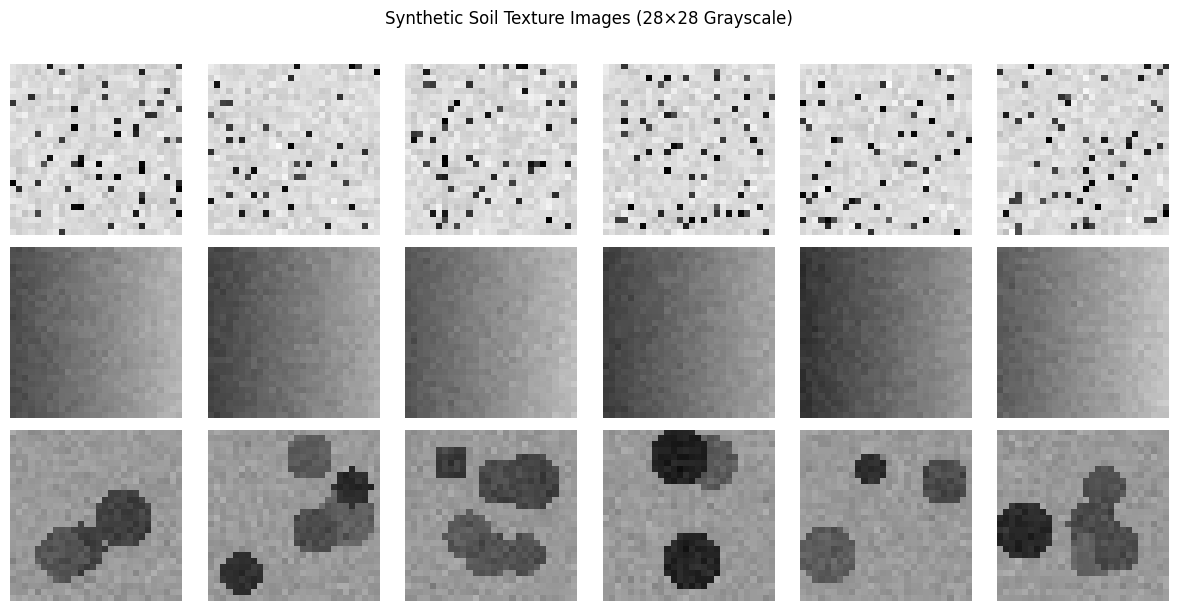

Sand:   sparse dark dots on light background (random grain distribution)
Clay:   smooth horizontal gradient (homogeneous fine-grained texture)
Gravel: large circular dark blobs on medium background (coarse particles)


In [2]:
# ─────────────────────────────────────────────────────────
# PART 2 — Visualise Sample Images
# ─────────────────────────────────────────────────────────
class_names = ['Sand', 'Clay', 'Gravel']

fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for cls in range(N_CLASSES):
    cls_imgs = all_images[all_labels == cls][:6]
    for col_idx, img in enumerate(cls_imgs):
        ax = axes[cls, col_idx]
        ax.imshow(img, cmap='gray', vmin=0, vmax=1)
        ax.axis('off')
        if col_idx == 0:
            ax.set_ylabel(class_names[cls], fontsize=12, rotation=0, labelpad=40,
                          ha='right', va='center')

plt.suptitle('Synthetic Soil Texture Images (28×28 Grayscale)', y=1.01)
plt.tight_layout()
plt.show()

print("Sand:   sparse dark dots on light background (random grain distribution)")
print("Clay:   smooth horizontal gradient (homogeneous fine-grained texture)")
print("Gravel: large circular dark blobs on medium background (coarse particles)")

---
## Part 3 | DataLoader Setup

In [3]:
# ─────────────────────────────────────────────────────────
# PART 3 — DataLoader (train/test split)
# ─────────────────────────────────────────────────────────

# PyTorch Conv2d expects (batch, channels, H, W)
X_tensor = torch.tensor(all_images, dtype=torch.float32).unsqueeze(1)  # (300, 1, 28, 28)
y_tensor = torch.tensor(all_labels, dtype=torch.long)                   # (300,)

# Train: 240 / Test: 60 (80/20 split)
split  = 240
X_tr   = X_tensor[:split];  y_tr = y_tensor[:split]
X_te   = X_tensor[split:];  y_te = y_tensor[split:]

tr_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=32, shuffle=True)
te_loader = DataLoader(TensorDataset(X_te, y_te), batch_size=32)

print(f"Training: {X_tr.shape}   Test: {X_te.shape}")
print(f"Mini-batch shape: {next(iter(tr_loader))[0].shape}")

Training: torch.Size([240, 1, 28, 28])   Test: torch.Size([60, 1, 28, 28])
Mini-batch shape: torch.Size([32, 1, 28, 28])


---
## Part 4 | 2D CNN Architecture

In [4]:
# ─────────────────────────────────────────────────────────
# PART 4 — SoilTextureCNN Architecture
# ─────────────────────────────────────────────────────────

class SoilTextureCNN(nn.Module):
    """
    2D CNN for 28×28 grayscale soil texture classification.

    Architecture flow:
      Input: (B, 1, 28, 28)
      Conv2d(1, 16, 3, pad=1) -> ReLU -> MaxPool2d(2)     [→ (B, 16, 14, 14)]
      Conv2d(16, 32, 3, pad=1) -> ReLU -> MaxPool2d(2)    [→ (B, 32, 7, 7)]
      Flatten                                              [→ (B, 32*7*7) = (B, 1568)]
      Linear(1568, 128) -> ReLU
      Linear(128, 3)                                       [→ 3 class logits]
    """
    def __init__(self):
        super().__init__()
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 28 -> 14
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 14 -> 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 3)
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        return self.classifier(x)

    def get_features(self, x):
        """Return feature maps after each conv block for visualisation."""
        f1 = self.conv_block1(x)
        f2 = self.conv_block2(f1)
        return f1, f2

model = SoilTextureCNN()
total_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nTotal parameters: {total_params:,}")

# Verify shapes through the network
dummy = torch.zeros(4, 1, 28, 28)
f1, f2 = model.get_features(dummy)
out    = model(dummy)
print(f"\nInput:       {dummy.shape}")
print(f"After block1: {f1.shape}")
print(f"After block2: {f2.shape}")
print(f"Output:       {out.shape}")

SoilTextureCNN(
  (conv_block1): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=3, bias=True)
  )
)

Total parameters: 206,019

Input:       torch.Size([4, 1, 28, 28])
After block1: torch.Size([4, 16, 14, 14])
After block2: torch.Size([4, 32, 7, 7])
Output:       torch.Size([4, 3])


---
## Part 5 | Training Loop

Epoch  10/40 | Loss: 0.0004 | Acc: 100.0%


Epoch  20/40 | Loss: 0.0001 | Acc: 100.0%


Epoch  30/40 | Loss: 0.0000 | Acc: 100.0%


Epoch  40/40 | Loss: 0.0000 | Acc: 100.0%


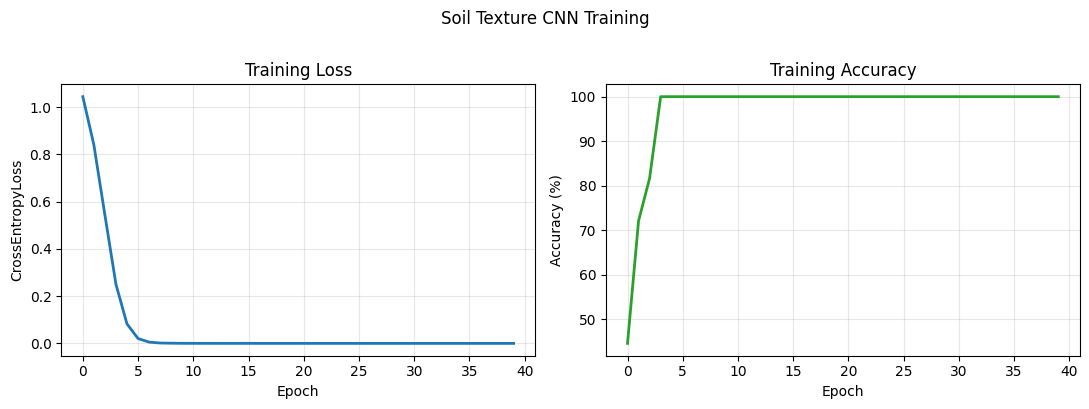

In [5]:
# ─────────────────────────────────────────────────────────
# PART 5 — Training the Soil Texture CNN
# ─────────────────────────────────────────────────────────

torch.manual_seed(0)
model     = SoilTextureCNN()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
EPOCHS    = 40

tr_loss_hist, tr_acc_hist = [], []

for epoch in range(EPOCHS):
    model.train()
    total_loss, correct = 0.0, 0
    for xb, yb in tr_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss   = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
        correct    += (logits.argmax(1) == yb).sum().item()

    avg_loss = total_loss / len(X_tr)
    avg_acc  = correct / len(X_tr)
    tr_loss_hist.append(avg_loss)
    tr_acc_hist.append(avg_acc)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS} | Loss: {avg_loss:.4f} | Acc: {avg_acc*100:.1f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(tr_loss_hist, lw=2, color='C0')
ax1.set_title('Training Loss'); ax1.set_xlabel('Epoch')
ax1.set_ylabel('CrossEntropyLoss'); ax1.grid(True, alpha=0.3)

ax2.plot([a*100 for a in tr_acc_hist], lw=2, color='C2')
ax2.set_title('Training Accuracy'); ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)'); ax2.grid(True, alpha=0.3)

plt.suptitle('Soil Texture CNN Training', y=1.01)
plt.tight_layout()
plt.show()

---
## Part 6 | Evaluation & Confusion Matrix

Test accuracy: 100.0%  (60/60 correct)


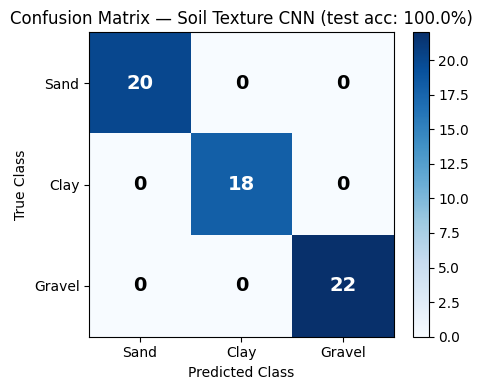


Per-class accuracy:
  Sand   : 100%  (20/20 correct)
  Clay   : 100%  (18/18 correct)
  Gravel : 100%  (22/22 correct)


In [6]:
# ─────────────────────────────────────────────────────────
# PART 6 — Test Evaluation & Confusion Matrix
# ─────────────────────────────────────────────────────────

model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for xb, yb in te_loader:
        preds = model(xb).argmax(1)
        all_preds.extend(preds.numpy())
        all_true.extend(yb.numpy())

all_preds = np.array(all_preds)
all_true  = np.array(all_true)
test_acc  = (all_preds == all_true).mean()

print(f"Test accuracy: {test_acc*100:.1f}%  ({int(test_acc*60)}/60 correct)")

# Confusion matrix
conf_mat = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
for t, p in zip(all_true, all_preds):
    conf_mat[t, p] += 1

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(conf_mat, cmap='Blues')
ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
ax.set_xticklabels(class_names); ax.set_yticklabels(class_names)
ax.set_xlabel('Predicted Class')
ax.set_ylabel('True Class')
ax.set_title(f'Confusion Matrix — Soil Texture CNN (test acc: {test_acc*100:.1f}%)')

for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, str(conf_mat[i, j]), ha='center', va='center',
                color='white' if conf_mat[i, j] > conf_mat.max() // 2 else 'black',
                fontsize=14, fontweight='bold')

plt.colorbar(im)
plt.tight_layout()
plt.show()

print("\nPer-class accuracy:")
for cls in range(N_CLASSES):
    mask = all_true == cls
    cls_acc = (all_preds[mask] == cls).mean() * 100
    print(f"  {class_names[cls]:7s}: {cls_acc:.0f}%  ({conf_mat[cls, cls]}/{mask.sum()} correct)")

---
## Part 7 | Visualising Learned Filters (Conv Block 1)

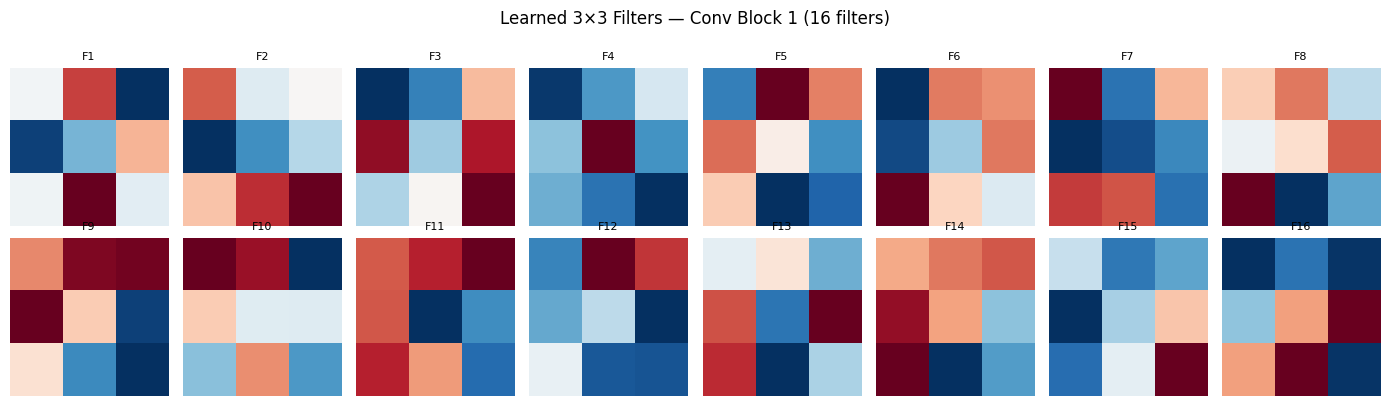

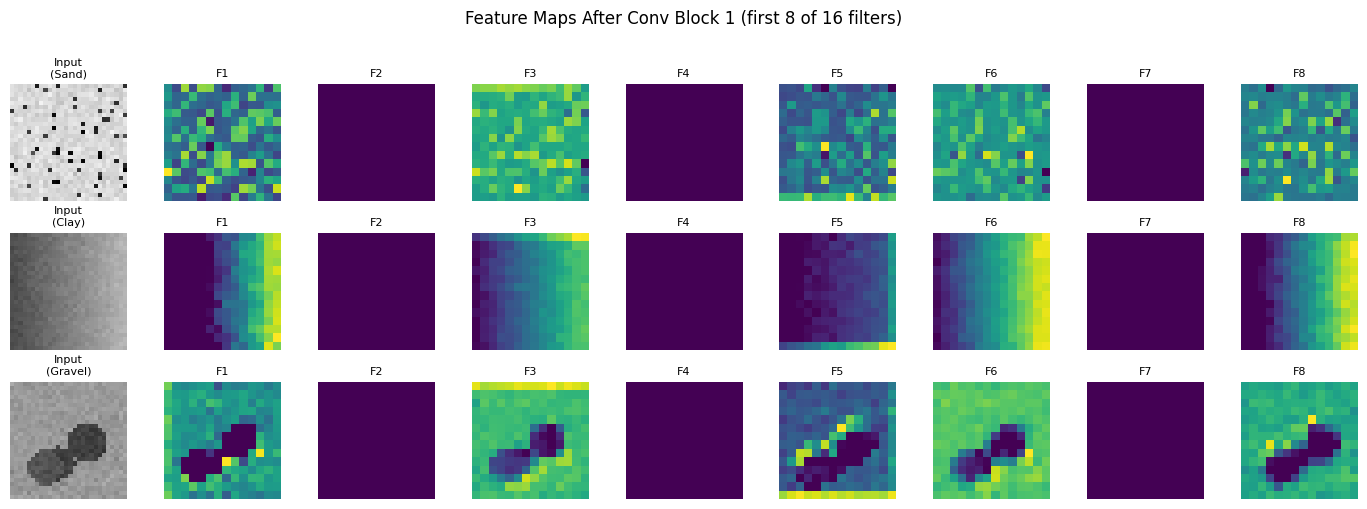

In [7]:
# ─────────────────────────────────────────────────────────
# PART 7 — Visualise Learned Filters and Feature Maps
# ─────────────────────────────────────────────────────────

# Show the 16 learned 3×3 filters from Conv block 1
filters = model.conv_block1[0].weight.data.squeeze(1)  # (16, 3, 3)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    f = filters[i].numpy()
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)   # normalise for display
    ax.imshow(f, cmap='RdBu_r', vmin=0, vmax=1)
    ax.set_title(f'F{i+1}', fontsize=8)
    ax.axis('off')

plt.suptitle('Learned 3×3 Filters — Conv Block 1 (16 filters)', y=1.01)
plt.tight_layout()
plt.show()

# Show feature maps for one sand and one gravel image
fig, axes = plt.subplots(3, 9, figsize=(14, 5))
for row_idx, cls in enumerate(range(N_CLASSES)):
    sample_img = X_tensor[y_tensor == cls][0:1]   # (1, 1, 28, 28)
    model.eval()
    with torch.no_grad():
        fmaps = model.conv_block1(sample_img).squeeze(0)  # (16, 14, 14)

    # Show input + first 8 feature maps
    axes[row_idx, 0].imshow(sample_img.squeeze().numpy(), cmap='gray', vmin=0, vmax=1)
    axes[row_idx, 0].set_title(f'Input\n({class_names[cls]})', fontsize=8)
    axes[row_idx, 0].axis('off')

    for fi in range(8):
        fm = fmaps[fi].numpy()
        axes[row_idx, fi+1].imshow(fm, cmap='viridis')
        axes[row_idx, fi+1].set_title(f'F{fi+1}', fontsize=8)
        axes[row_idx, fi+1].axis('off')

plt.suptitle('Feature Maps After Conv Block 1 (first 8 of 16 filters)', y=1.01)
plt.tight_layout()
plt.show()

---
## Practice Exercises

1. **More complex textures** — Modify `make_gravel_image()` to add elliptical instead of circular blobs (using `cv2.ellipse` or NumPy rotation). Does accuracy change?
2. **Add a third conv block** — Insert `Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)` before the classifier. Recalculate the flatten size (64 × 3 × 3 = 576). Does deeper help on 28×28 images?
3. **Dropout in classifier** — Add `nn.Dropout(0.5)` before the final Linear layer. Does test accuracy improve?
4. **Data augmentation** — Add random horizontal flips and brightness jitter to training images. Does this help the model generalise?
5. **Larger images** — Scale up to 64×64 images with more detail. How does the model need to change?

In [8]:
# ─────────────────────────────────────────────────────────
# PRACTICE — Starter code
# ─────────────────────────────────────────────────────────

# Exercise 3: Dropout in classifier
# class SoilTextureCNNDropout(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.conv_block1 = nn.Sequential(
#             nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
#         )
#         self.conv_block2 = nn.Sequential(
#             nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
#         )
#         self.classifier = nn.Sequential(
#             nn.Flatten(),
#             nn.Linear(32*7*7, 128), nn.ReLU(),
#             nn.Dropout(0.5),        # <-- added
#             nn.Linear(128, 3)
#         )
#     def forward(self, x):
#         return self.classifier(self.conv_block2(self.conv_block1(x)))

# Exercise 4: Manual random flip augmentation
# def augment(x):
#     if torch.rand(1) > 0.5:
#         x = torch.flip(x, dims=[-1])   # horizontal flip
#     return x

print("Practice exercise starters are ready — uncomment and complete!")

Practice exercise starters are ready — uncomment and complete!


---
## ML Connection Table

| Geotechnical Task | CNN Input | Conv Layers | Loss | Notes |
|---|---|---|---|---|
| Soil texture classification | Microscopy image | 2–3 Conv2d blocks | CrossEntropyLoss | Sand / clay / gravel |
| Crack detection | Site photograph | 2D CNN + sigmoid head | BCEWithLogitsLoss | Binary: crack / no-crack |
| Settlement contour map | 2D field measurement grid | Encoder-Decoder CNN | MSELoss | Pixel-level regression |
| CPT profile classification | Depth sequence | 1D Conv blocks (Day 68) | CrossEntropyLoss | Per-profile label |
| Rock joint roughness | Surface scan image | 2D CNN regression | HuberLoss | JRC coefficient output |

---
## Key Takeaways

1. **2D CNN** is the standard tool for soil texture image classification — Conv2d slides a 2D filter over the spatial image, detecting edges, grain boundaries, and texture gradients.
2. **MaxPool2d(2)** halves both height and width at each stage, progressively making features more position-invariant — a grain shifted a few pixels still activates the same filters.
3. **Feature hierarchy** is the key power: Block 1 learns dots and edges; Block 2 learns spatial arrangements of those dots — directly mapping to grain distribution patterns.
4. **The confusion matrix** reveals which soil textures the model confuses — in real applications, sand and gravel can look similar in certain lighting, requiring domain-aware augmentation.
5. Filter visualisation shows that the learned weights are task-specific texture detectors, not generic features — the CNN is building a geotechnical visual vocabulary.

---
*Day 069 of 100 — Every CNN filter is learning to see the geology, one pixel at a time.*